# Неделя 2 — данные для прогноза пассажиропотока

**Гущин Михаил (Data Engineer)** · Сокольническая линия, 26 станций, январь 2023 — октябрь 2026

Запуск: открыть в VS Code и нажать **Run All**. Нужно, чтобы данные уже были скачаны
(`dvc repro` из корня проекта). Если папки `data/` нет, первая ячейка скачает данные сама.

Что покажем:
1. Реальные данные data.mos.ru — квартальные входы по станциям
2. Почасовые данные: синтетика, откалиброванная по реальным кварталам
3. Суточные профили станций разного типа
4. Рабочая суббота — что даёт производственный календарь
5. Реальная погода и праздники
6. Проверки качества перед загрузкой в базу

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from metro import opendata, synth, validate
from metro.stations import STATION_BY_ID, STATIONS

EXT, RAW = ROOT / "data" / "external", ROOT / "data" / "raw"
P = yaml.safe_load(open(ROOT / "params.yaml", encoding="utf-8"))["data"]
START, END = P["start"], P["end"]  # период данных — из params.yaml, как в DVC
if not (RAW / "ridership.parquet").exists():  # данных нет — скачиваем и генерируем (≈1 мин)
    EXT.mkdir(parents=True, exist_ok=True)
    RAW.mkdir(parents=True, exist_ok=True)
    for name, df in (("metro_quarterly", opendata.fetch_metro_quarterly()),
                     ("weather", opendata.fetch_weather(START, END)),
                     ("calendar", opendata.fetch_calendar(START, END))):
        df.to_parquet(EXT / f"{name}.parquet", index=False)
    cal = pd.read_parquet(EXT / "calendar.parquet")
    bases = synth.calibrate_bases(pd.read_parquet(EXT / "metro_quarterly.parquet"), cal,
                                  START, END)
    for name, df in synth.generate(START, END, weather=pd.read_parquet(EXT / "weather.parquet"),
                                   calendar=cal, bases=bases).items():
        df.to_parquet(RAW / f"{name}.parquet", index=False)

quarterly = pd.read_parquet(EXT / "metro_quarterly.parquet")
raw = validate.load(RAW)
rid, weather, calendar = raw["ridership"].copy(), raw["weather"], raw["calendar"]
rid["date"] = pd.to_datetime(rid["date"])
rid["station"] = rid["station_id"].map(lambda i: STATION_BY_ID[i]["name"])

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"Период: {START} — {END}")
print(f"Реальные квартальные данные: {len(quarterly):,} строк, {quarterly['line'].nunique()} линий")
print(f"Почасовые данные: {len(rid):,} строк = {rid['date'].nunique()} дней × 19 часов × {len(STATIONS)} станций")

Период: 2023-01-01 — 2026-10-27
Реальные квартальные данные: 6,083 строк, 18 линий
Почасовые данные: 689,624 строк = 1396 дней × 19 часов × 26 станций


## 1. Реальные данные: data.mos.ru

Набор 62743 «Пассажиропоток по станциям Московского метрополитена» содержит **входы и выходы
по каждой станции за квартал**. Почасовых данных в открытом доступе нет. Ниже — Сокольническая
линия, тысячи входов за квартал.

In [2]:
line = quarterly[(quarterly["line"] == "Сокольническая линия") & quarterly["year"].between(int(START[:4]), int(END[:4]))]
table = line.pivot_table(index="station", columns=["year", "quarter"], values="entries", aggfunc="sum")
order = [s["name"] for s in STATIONS if s["name"] in table.index] + \
        [n for n in table.index if n not in {s["name"] for s in STATIONS}]
(table.loc[order] / 1000).round(0).style.format("{:,.0f}", na_rep="—") \
    .background_gradient(cmap="Blues", axis=None).set_caption("Входы, тыс. за квартал (— нет данных)")

Что видно сразу:
- у **«Библиотеки имени Ленина»** входы нулевые: на пересадочных узлах входы, видимо, считаются на соседней станции;
- **«Потапово»** открыта в 2024 году, в нашем справочнике её пока нет;
- **IV квартал** 2024 и 2025 годов неполный, по III кварталу 2026 пока опубликована одна станция;
- поток **«Новомосковской»** в 2025 году упал: часть пассажиров перешла на «Потапово».

## 2. Синтетика, откалиброванная по реальным кварталам

Почасовые ряды мы генерируем сами. Объём каждой станции подобран так, чтобы суммы за кварталы
совпадали с data.mos.ru. Проверка: складываем нашу синтетику по кварталам и сравниваем с реальностью.

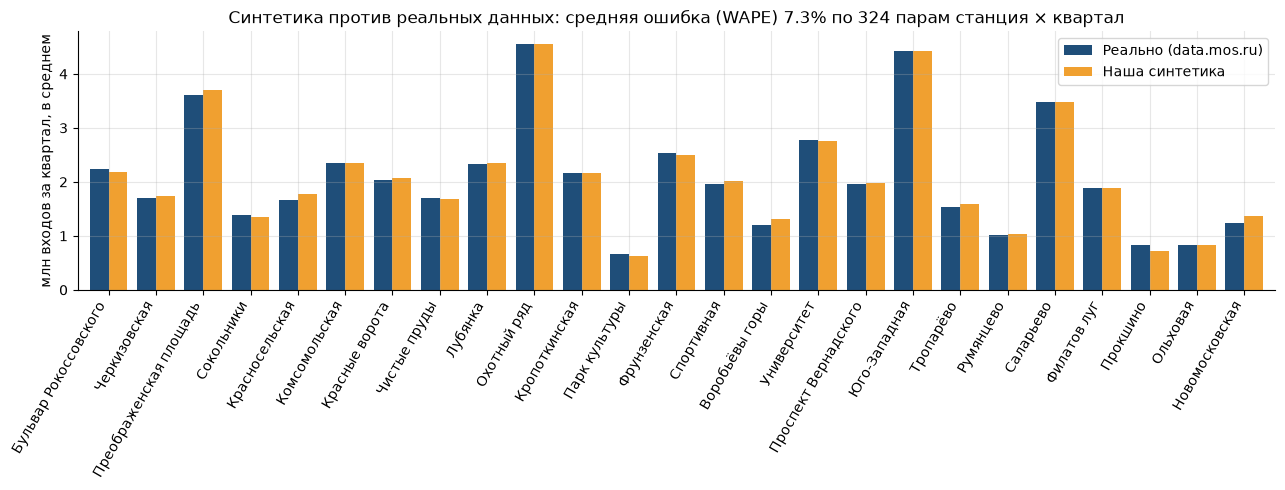

In [3]:
rid["year"], rid["quarter"] = rid["date"].dt.year, rid["date"].dt.quarter
syn_q = rid.groupby(["station", "year", "quarter"], as_index=False)["passengers"].sum()
cmp = syn_q.merge(line[line["entries"] > 0], on=["station", "year", "quarter"])
wape = (cmp["passengers"] - cmp["entries"]).abs().sum() / cmp["entries"].sum() * 100

avg = cmp.groupby("station")[["entries", "passengers"]].mean() / 1e6
avg = avg.loc[[s["name"] for s in STATIONS if s["name"] in avg.index]]
ax = avg.plot.bar(width=0.8, color=["#1f4e79", "#f0a030"], figsize=(13, 5))
ax.legend(["Реально (data.mos.ru)", "Наша синтетика"])
ax.set_ylabel("млн входов за квартал, в среднем")
ax.set_xlabel("")
ax.set_title(f"Синтетика против реальных данных: средняя ошибка (WAPE) {wape:.1f}% по {len(cmp)} парам станция × квартал")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()

## 3. Суточный профиль: спальный район против центра

Утром люди **входят** в метро у дома, вечером — у работы. Поэтому пики у станций разного
типа приходятся на разное время.

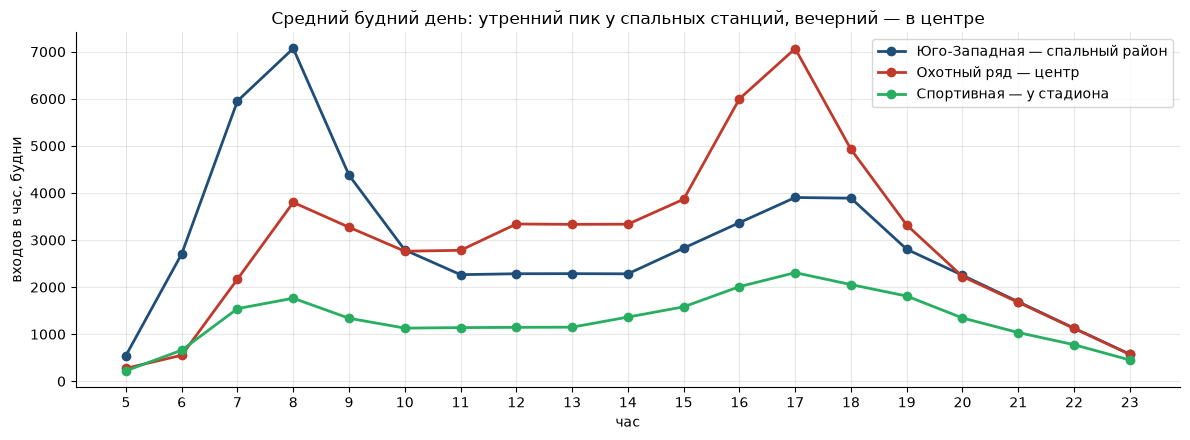

In [4]:
wd = rid[rid["date"].dt.dayofweek < 5]
fig, ax = plt.subplots()
for name, kind, color in (("Юго-Западная", "спальный район", "#1f4e79"),
                          ("Охотный ряд", "центр", "#c0392b"), ("Спортивная", "у стадиона", "#27ae60")):
    prof = wd[wd["station"] == name].groupby("hour")["passengers"].mean()
    ax.plot(prof.index, prof.values, marker="o", lw=2, color=color, label=f"{name} — {kind}")
ax.set_xticks(range(5, 24))
ax.set_xlabel("час")
ax.set_ylabel("входов в час, будни")
ax.set_title("Средний будний день: утренний пик у спальных станций, вечерний — в центре")
ax.legend()
plt.tight_layout()

## 4. Рабочая суббота

По производственному календарю **1 ноября 2025 — рабочая суббота** (перенос ради длинных
ноябрьских выходных). Календарь мы берём с isdayoff.ru, поэтому в этот день поток как в будни,
с утренним пиком. Проверка качества сначала приняла такие часы за выбросы. Так мы нашли, что
в схеме не хватает признака «рабочий/нерабочий день», и добавили столбец `is_dayoff`.

Рабочие субботы 2023–2026: 27.04.2024, 02.11.2024, 28.12.2024, 01.11.2025


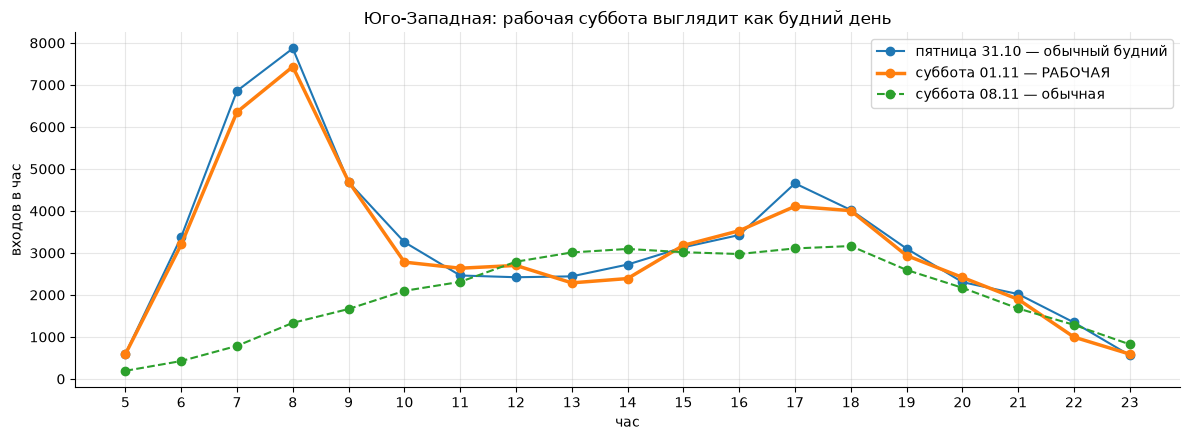

In [5]:
st = rid[rid["station"] == "Юго-Западная"]
fig, ax = plt.subplots()
for day, label, style in (("2025-10-31", "пятница 31.10 — обычный будний", "-"),
                          ("2025-11-01", "суббота 01.11 — РАБОЧАЯ", "-"),
                          ("2025-11-08", "суббота 08.11 — обычная", "--")):
    d = st[st["date"] == day]
    ax.plot(d["hour"], d["passengers"], style, marker="o", lw=2.5 if "РАБОЧАЯ" in label else 1.5, label=label)
ax.set_xticks(range(5, 24))
ax.set_xlabel("час")
ax.set_ylabel("входов в час")
ax.set_title("Юго-Западная: рабочая суббота выглядит как будний день")
ax.legend()
plt.tight_layout()

cal = calendar.assign(date=pd.to_datetime(calendar["date"]))
print(f"Рабочие субботы {START[:4]}–{END[:4]}:",
      ", ".join(cal[(~cal["is_dayoff"]) & (cal["date"].dt.dayofweek == 5)]["date"].dt.strftime("%d.%m.%Y")))

## 5. Поток по линии за весь период, погода и праздники

Погода — реальная (Open-Meteo, архив ERA5 по Москве), праздники — из производственного календаря.

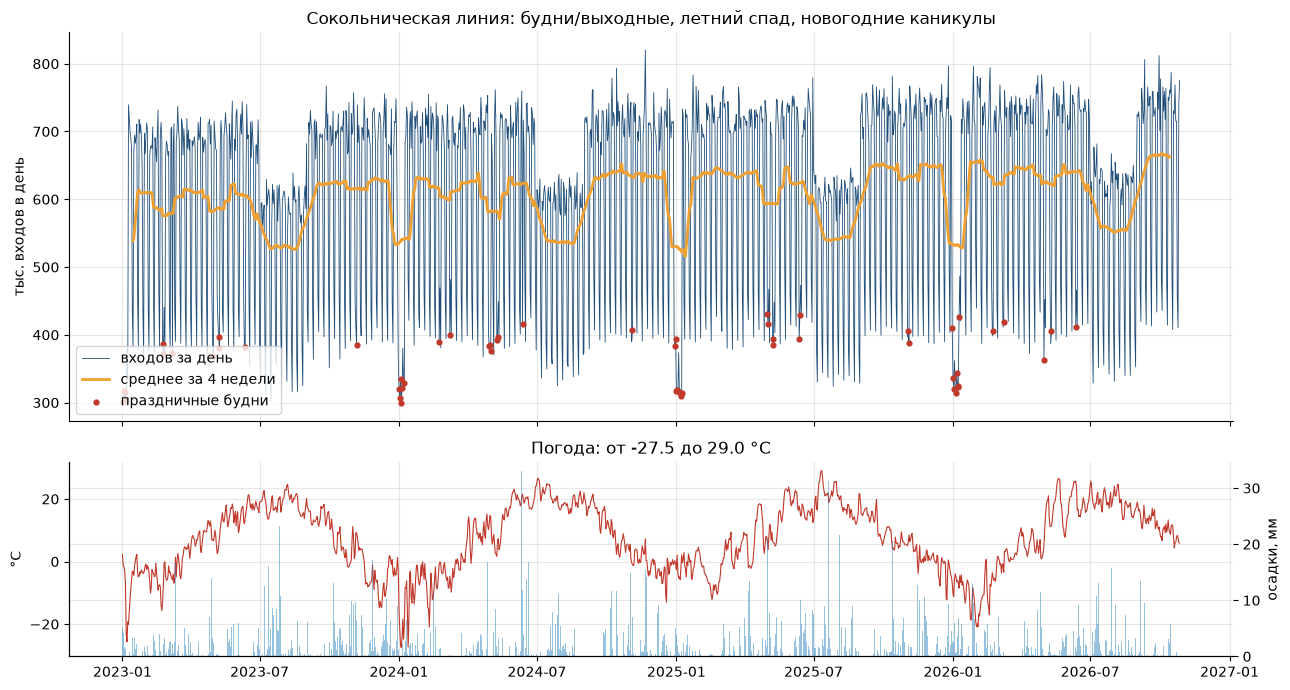

In [6]:
daily = rid.groupby("date")["passengers"].sum() / 1e3
w = weather.assign(date=pd.to_datetime(weather["date"])).set_index("date")
hol = cal[cal["is_holiday"]]["date"]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
a1.plot(daily.index, daily.values, lw=0.6, color="#1f4e79", label="входов за день")
a1.plot(daily.rolling(28, center=True).mean(), color="#f0a030", lw=2, label="среднее за 4 недели")
a1.scatter(hol, daily.reindex(hol), color="#c0392b", s=12, zorder=3, label="праздничные будни")
a1.set_ylabel("тыс. входов в день")
a1.set_title("Сокольническая линия: будни/выходные, летний спад, новогодние каникулы")
a1.legend(loc="lower left")
a2.plot(w.index, w["temp_c"], color="#c0392b", lw=0.8)
a2.set_ylabel("°C")
a2b = a2.twinx()
a2b.bar(w.index, w["precip_mm"], color="#2e86c1", alpha=0.5, width=1)
a2b.set_ylabel("осадки, мм")
a2.set_title(f"Погода: от {w['temp_c'].min():.1f} до {w['temp_c'].max():.1f} °C")
plt.tight_layout()

## 6. Проверки качества перед загрузкой в базу

ETL не загружает данные, если есть хотя бы одна **ошибка**: схема, пропуски, дубли,
дыры в датах, неполная сетка «день × час × станция», значения вне пределов.
**Предупреждения** загрузку не блокируют, но их надо знать.

In [7]:
issues = validate.check_raw(raw) + validate.check_quarterly(quarterly)
report = pd.DataFrame([vars(i) for i in issues]) if issues else pd.DataFrame(columns=["level", "table", "check", "detail"])
print(f"Ошибок: {(report['level'] == 'error').sum()}, предупреждений: {(report['level'] == 'warning').sum()}")
report

Ошибок: 0, предупреждений: 6


,level,table,check,detail
0,warning,metro_quarterly,stations,"есть в data.mos.ru, нет в справочнике: ['Потап..."
1,warning,metro_quarterly,zeros,нулевые входы: ['Библиотека имени Ленина']
2,warning,metro_quarterly,completeness,2021 Q3: 21 станций из 27
3,warning,metro_quarterly,completeness,2024 Q4: 15 станций из 27
4,warning,metro_quarterly,completeness,2025 Q4: 11 станций из 27
5,warning,metro_quarterly,completeness,2026 Q3: 1 станций из 27


In [8]:
# Что поймает проверка: удалим один час и продублируем строку
broken = {**raw, "ridership": pd.concat([raw["ridership"].iloc[1:], raw["ridership"].head(2)])}
pd.DataFrame([vars(i) for i in validate.check_raw(broken) if i.level == "error"])

,level,table,check,detail
0,error,ridership,duplicates,"1 дублей по ключу ['date', 'hour', 'station_id']"
1,error,ridership,grid,"689625 строк, ожидалось 689624 (дни × часы × с..."


## Итог недели 2

| Что | Результат |
|---|---|
| Источники | data.mos.ru (пассажиропоток), Open-Meteo (погода), isdayoff.ru (календарь) — без ключей |
| Почасовые данные | 689 624 строки (01.2023–10.2026), объёмы станций откалиброваны по реальным кварталам |
| Проверки | 0 ошибок; предупреждения — про неполноту данных data.mos.ru |
| Загрузка в PostgreSQL | одна транзакция, при ошибке данные в БД не портятся |
| Воспроизводимость | DVC: `dvc repro` → fetch → synth → validate |

**Дальше (неделя 3, Айтметов Акрам):** EDA и признаки, включая новый признак рабочего дня `is_dayoff`.